# 05 — Điền tuổi & xuất kết quả

Notebook này dùng model đã train (`artifacts/lgbm_age.txt`) để dự đoán cho **15.861 khách thiếu age**,
xuất CSV và sinh báo cáo Markdown.

> Nếu bạn vừa chạy `04_training.ipynb` với `TRAIN_FROM_SCRATCH = True`, model cuối cùng đã được
> train lại trên **toàn bộ** khách có nhãn (không phải chỉ 1 fold) và lưu sẵn. Notebook này chỉ
> dùng lại nó, không train thêm.

In [1]:
import sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# Notebook có thể được mở từ thư mục notebooks/ hoặc từ gốc repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

CUSTOMERS = ROOT / "customers.csv"
ARTICLES = ROOT / "articles.csv"
TXN = ROOT / "transactions_train.csv"
ARTIFACTS = ROOT / "artifacts"
OUTPUTS = ROOT / "outputs"

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("polars", pl.__version__, "| numpy", np.__version__, "| ROOT =", ROOT)

polars 2.1.0 | numpy 2.3.5 | ROOT = E:\download\age_imputation


In [2]:
import numpy as np
import polars as pl

import src.config as C

pred = np.load(OUTPUTS / "pred_missing.npy")
rows = np.load(OUTPUTS / "missing_rows.npy")
print(f"{rows.size:,} khách thiếu age | dự đoán: min={pred.min():.1f}, max={pred.max():.1f}, mean={pred.mean():.1f}")

15,861 khách thiếu age | dự đoán: min=17.8, max=68.6, mean=37.7


## Vì sao dự đoán bị "co" vào khoảng 18–69 tuổi?

Nhóm **thiếu age** không phải mẫu ngẫu nhiên của toàn bộ khách: họ ít hoạt động hơn (median 4 giao dịch
so với 9), tức ít dữ liệu hành vi hơn → mô hình dự đoán **thận trọng hơn**, gần với nhóm tuổi trung bình.

Điều này **không sai về mặt thống kê**: với dữ liệu yếu, dự đoán gần trung bình là tối ưu cho MAE.
Nhưng nếu dùng để suy luận "không có khách nào trên 70 tuổi", thì đó là kết luận sai — cần nêu rõ
trong báo cáo.

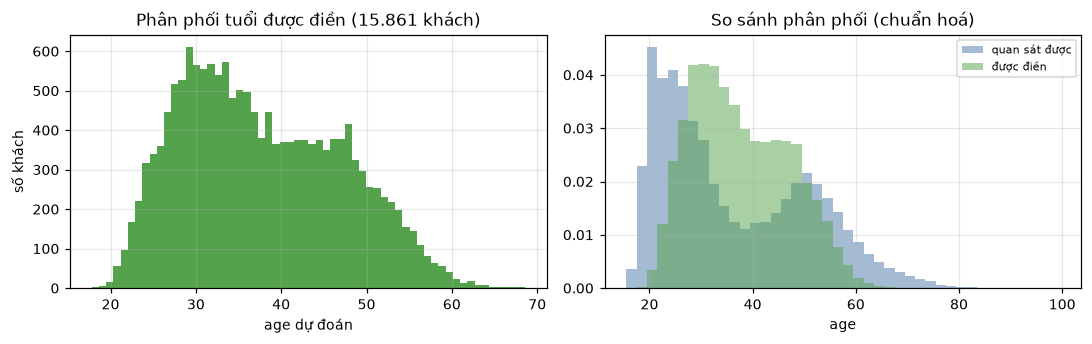

quan sát : mean=36.4 std=14.3 p5=19 p95=62
được điền: mean=37.7 std=9.3 p5=24 p95=54


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))

axes[0].hist(pred, bins=60, color="#54A24B")
axes[0].set_title("Phân phối tuổi được điền (15.861 khách)")
axes[0].set_xlabel("age dự đoán")
axes[0].set_ylabel("số khách")

obs = pl.read_parquet(C.ARTIFACTS / "customers_base.parquet", columns=["age"])["age"].drop_nulls().to_numpy()
axes[1].hist(obs, bins=np.arange(15.5, 100.5, 2), density=True, alpha=0.5, label="quan sát được", color="#4C78A8")
axes[1].hist(pred, bins=np.arange(15.5, 100.5, 2), density=True, alpha=0.5, label="được điền", color="#54A24B")
axes[1].set_title("So sánh phân phối (chuẩn hoá)")
axes[1].set_xlabel("age")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

print(f"quan sát : mean={obs.mean():.1f} std={obs.std():.1f} p5={np.percentile(obs,5):.0f} p95={np.percentile(obs,95):.0f}")
print(f"được điền: mean={pred.mean():.1f} std={pred.std():.1f} p5={np.percentile(pred,5):.0f} p95={np.percentile(pred,95):.0f}")

## Xuất file kết quả

`src/impute.py` ghép dự đoán vào bảng khách hàng gốc, **giữ nguyên thứ tự dòng** và giữ nguyên
giá trị `age` gốc ở những dòng đã có:

| Cột | Ý nghĩa |
|---|---|
| `customer_id` | khoá khách hàng |
| `age_original` | tuổi gốc; **null** nếu vốn thiếu |
| `age_filled` | tuổi sau khi điền (giá trị gốc nếu đã có) |
| `age_source` | `observed` hoặc `imputed` |

In [4]:
from src.impute import main as run_impute

run_impute()

out = pl.read_csv(C.IMPUTED_CSV, schema_overrides={"customer_id": pl.String})
print(f"\n{out.height:,} dòng | cột: {out.columns}")
out.head(5)

wrote 1,371,980 rows -> E:\download\age_imputation\outputs\customers_age_imputed.csv
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ age_filled │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 15861.0    │
│ null_count ┆ 0.0        │
│ mean       ┆ 37.710548  │
│ std        ┆ 9.331709   │
│ min        ┆ 17.799999  │
│ 25%        ┆ 30.09      │
│ 50%        ┆ 36.369999  │
│ 75%        ┆ 45.060001  │
│ max        ┆ 68.589996  │
└────────────┴────────────┘

1,371,980 dòng | cột: ['customer_id', 'age_original', 'age_filled', 'age_source']


customer_id,age_original,age_filled,age_source
str,f64,f64,str
"""00000dbacae5abe5e23885899a1fa4…",49.0,49.0,"""observed"""
"""0000423b00ade91418cceaf3b26c6a…",25.0,25.0,"""observed"""
"""000058a12d5b43e67d225668fa1f8d…",24.0,24.0,"""observed"""
"""00005ca1c9ed5f5146b52ac8639a40…",54.0,54.0,"""observed"""
"""00006413d8573cd20ed7128e53b7b1…",52.0,52.0,"""observed"""


In [5]:
out.filter(pl.col("age_source") == "imputed").head(5)

customer_id,age_original,age_filled,age_source
str,f64,f64,str
"""000064249685c11552da43ef22a503…",null,30.7,"""imputed"""
"""0002b9088196900626214bcdc6d5f3…",null,25.93,"""imputed"""
"""0004690d2b68d5175697d197a86065…",null,49.02,"""imputed"""
"""0005cd85a6220e1f1c582c7ff9175e…",null,36.53,"""imputed"""
"""00060d2f1e63f2b95268b8573996b9…",null,38.21,"""imputed"""


## Kiểm tra tính đúng đắn của file

Bốn điều phải đúng:

1. Đủ 1.371.980 dòng và giữ nguyên thứ tự `customer_id` như file gốc.
2. Mọi giá trị `age` gốc **không bị thay đổi**.
3. Đúng 15.861 dòng được đánh dấu `imputed`, và tất cả đều có `age_filled`.
4. Không có `age_filled` nào bị null/ngoài khoảng [16, 99].

In [6]:
src = pl.read_csv(C.CUSTOMERS_CSV, schema_overrides={"customer_id": pl.String, "age": pl.Float32})

assert out.height == src.height, "Sai số dòng!"
assert (out["customer_id"] == src["customer_id"]).all(), "Sai thứ tự customer_id!"

mask_obs = src["age"].is_not_null()
assert np.allclose(out["age_original"].fill_null(-1).to_numpy(), src["age"].fill_null(-1).to_numpy(), atol=1e-4), \
    "Giá trị age gốc bị thay đổi!"
assert np.allclose(
    out.filter(mask_obs)["age_filled"].to_numpy(), src["age"].drop_nulls().to_numpy(), atol=1e-4
), "age_filled của nhóm quan sát bị thay đổi!"

n_imputed = (out["age_source"] == "imputed").sum()
assert n_imputed == src["age"].is_null().sum(), "Sai số dòng imputed!"
assert out["age_filled"].is_null().sum() == 0, "Còn null trong age_filled!"

imp_only = out.filter(pl.col("age_source") == "imputed")["age_filled"]
assert imp_only.min() >= C.AGE_MIN and imp_only.max() <= C.AGE_MAX, "Dự đoán ra ngoài khoảng tuổi!"

print("✅ Tất cả kiểm tra đều đạt")
print(f"   dòng: {out.height:,} | quan sát: {int(mask_obs.sum()):,} | đã điền: {n_imputed:,}")
print(f"   khoảng tuổi ĐƯỢC ĐIỀN: [{imp_only.min():.1f}, {imp_only.max():.1f}] (trung bình {imp_only.mean():.1f})")
print(f"   khoảng cột age_filled (gồm cả quan sát): [{out['age_filled'].min():.1f}, {out['age_filled'].max():.1f}]")

✅ Tất cả kiểm tra đều đạt
   dòng: 1,371,980 | quan sát: 1,356,119 | đã điền: 15,861
   khoảng tuổi ĐƯỢC ĐIỀN: [17.8, 68.6] (trung bình 37.7)
   khoảng cột age_filled (gồm cả quan sát): [16.0, 99.0]


## Sinh báo cáo Markdown

`src/report.py` tổng hợp mọi số liệu (CV theo fold, baseline, sai số theo nhóm tuổi, feature
importance, phần tóm tắt EDA) thành `outputs/age_imputation_report.md`.

In [7]:
from src.report import main as run_report

run_report()
print()
print((C.OUTPUTS / "age_imputation_report.md").read_text(encoding="utf-8")[:2500])

wrote E:\download\age_imputation\outputs\age_imputation_report.md

# Age Imputation — H&M Personalized Fashion Recommendations

## 1. Bài toán

| | |
|---|---|
| Khách hàng | 1,371,980 |
| Có `age` | 1,356,119 (98.84%) |
| **Thiếu `age`** | **15,861 (1.16%)** |
| Giao dịch dùng làm feature | 31,788,324 (2018-09-20 → 2020-09-22) |
| Khoảng tuổi | 16–99 |

Mục tiêu: dự đoán `age` cho 15,861 khách thiếu, dựa trên hành vi mua sắm và thuộc tính tài khoản.

## 2. Kiến trúc pipeline

```mermaid
flowchart TD
    A[customers.csv / articles.csv / transactions_train.csv] --> Z[eda.py<br/>EDA: missingness, phân phối, tín hiệu, trùng lặp]
    A --> B[prepare_data.py<br/>chuẩn hoá, mã hoá về số nguyên]
    Z -.->|quyết định feature & loss| B
    B --> C[transactions_compact.parquet<br/>31.8M dòng]
    B --> D[customers_base.parquet<br/>articles_encoded.parquet]
    C --> E[features.py<br/>RFM + tỷ trọng category + ma trận cust x article]
    D --> E
    E --> F[base features + cat_counts / lvl_* / c

## Kết quả cuối cùng

| Artifact | Nội dung |
|---|---|
| `outputs/customers_age_imputed.csv` | 1.371.980 khách, cột `age_filled` + `age_source` (110 MB) |
| `outputs/age_imputation_report.md` | báo cáo đầy đủ (CV, baseline, sai số theo nhóm, importance) |
| `outputs/eda_report.md` | báo cáo EDA (notebook 00) |
| `outputs/metrics.json` | toàn bộ số liệu dạng máy đọc |
| `artifacts/lgbm_age.txt` | model LightGBM cuối cùng |

### Cách dùng kết quả trong phân tích hạ nguồn

Nên dùng kèm cột `age_source` và cân nhắc **trọng số độ tin cậy**: khách có nhiều giao dịch được dự đoán
tốt hơn (MAE ~6 tuổi) so với khách ít giao dịch (~11 tuổi). Nếu phân tích của bạn nhạy với sai số,
hãy lọc theo `n_txn` hoặc báo cáo riêng hai nhóm.